# Fuzzy Energy-Management Controller (Sanjay)

**Role:** real-time supervisory controller for the 10,458-bus SimBench digital twin.

**Flow:** grid state (from AC power flow) -> fuzzification -> rule base -> defuzzification -> EV / battery / flexible-load commands -> second AC power flow.

This notebook is built in steps:

| Step | Content | Status |
|---|---|---|
| 1 | Inputs, outputs and ranges | done |
| 2 | Membership functions and plots | done |
| 3 | Rule base and rule firing | done |
| 4 | Defuzzification and tests | done |
| 5 | Controller function (common interface) | done |
| 6 | Apply commands to pandapower, second power flow | done (real run needs your environment) |
| 7 | OFF vs ON comparison on stressed scenarios | done (real run needs your environment) |

Fuzzy logic is hand-coded with NumPy only (no `scikit-fuzzy`), so there are no extra dependencies.

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt

os.makedirs("output", exist_ok=True)  # same output folder as the other modules

## Step 1 - Inputs and outputs

**Inputs (8)** come from the digital twin, prediction models, and optimization modules.

| Input | Unit | Range | Source |
|---|---|---|---|
| `v_min_pu` | pu | 0.85 - 1.10 | Digital twin power flow |
| `line_loading_pct` | % | 0 - 150 | Digital twin power flow |
| `trafo_loading_pct` | % | 0 - 150 | Digital twin power flow |
| `price_eur_mwh` | EUR/MWh | 0 - 120 | Sujit's Hybrid price forecast |
| `ev_load_mw` | MW | 0 - 3 | Jayanth's GA-optimized EV profile |
| `renewable_mw` | MW | 0 - 14 | Digital twin renewable generation |
| `battery_soc_pct` | % | 0 - 100 | Sarvesh's battery / PSO module |
| `stability_risk` | probability | 0 - 1 | Selected grid-stability ML model |

**Outputs (4)**

| Output | Unit | Range | Meaning |
|---|---|---|---|
| `ev_limit_pct` | % | 0 - 100 | Maximum permitted EV charging level |
| `battery_cmd` | rated-power fraction | -1 to +1 | + charge, - discharge |
| `flex_reduction_pct` | % | 0 - 30 | Flexible-load reduction |
| `grid_state_score` | 0 - 1 | 0 normal, 1 critical |

## Step 2 - Membership functions

Every set is a trapezoid `[a, b, c, d]` (rises a to b, flat b to c, falls c to d). A triangle is a trapezoid with `b = c`. Shoulder sets repeat the end value (for example `[0, 0, 30, 50]`).

Voltage limit used by the project: 0.95 pu. Loading above 100 % counts as an overload.

In [2]:
def trapmf(x, abcd):
    """Trapezoidal membership. Handles shoulders (a == b or c == d)."""
    a, b, c, d = abcd
    x = np.asarray(x, dtype=float)
    up = np.where(x >= b, 1.0, np.where(x <= a, 0.0, (x - a) / max(b - a, 1e-12)))
    down = np.where(x <= c, 1.0, np.where(x >= d, 0.0, (d - x) / max(d - c, 1e-12)))
    return np.clip(np.minimum(up, down), 0.0, 1.0)


# Each variable: universe (min, max, unit) and its fuzzy sets
INPUTS = {
    "v_min_pu": {
        "range": (0.85, 1.10), "unit": "pu",
        "sets": {
            "LOW":    [0.85, 0.85, 0.92, 0.96],
            "NORMAL": [0.94, 0.97, 1.03, 1.05],
            "HIGH":   [1.04, 1.06, 1.10, 1.10],
        },
    },
    "line_loading_pct": {
        "range": (0, 150), "unit": "%",
        "sets": {
            "LOW":        [0, 0, 30, 50],
            "NORMAL":     [30, 50, 70, 85],
            "HIGH":       [70, 85, 95, 105],
            "OVERLOADED": [95, 105, 150, 150],
        },
    },
    "trafo_loading_pct": {
        "range": (0, 150), "unit": "%",
        "sets": {
            "LOW":        [0, 0, 30, 50],
            "NORMAL":     [30, 50, 70, 85],
            "HIGH":       [70, 85, 95, 105],
            "OVERLOADED": [95, 105, 150, 150],
        },
    },
    "price_eur_mwh": {
        "range": (0, 120), "unit": "EUR/MWh",
        "sets": {
            "LOW":    [0, 0, 40, 50],
            "NORMAL": [40, 50, 62, 72],
            "HIGH":   [62, 72, 82, 90],
            "SPIKE":  [82, 90, 120, 120],
        },
    },
    "ev_load_mw": {
        "range": (0, 3), "unit": "MW",
        "sets": {
            "LOW":    [0, 0, 0.5, 1.0],
            "NORMAL": [0.5, 1.0, 1.5, 2.0],
            "HIGH":   [1.5, 2.0, 3.0, 3.0],
        },
    },
    "renewable_mw": {
        "range": (0, 14), "unit": "MW",
        "sets": {
            "LOW":    [0, 0, 2, 4],
            "MEDIUM": [2, 4, 6, 8],
            "HIGH":   [6, 8, 14, 14],
        },
    },
    "battery_soc_pct": {
        "range": (0, 100), "unit": "%",
        "sets": {
            "LOW":    [0, 0, 15, 30],
            "NORMAL": [20, 35, 65, 80],
            "HIGH":   [70, 85, 100, 100],
        },
    },
    "stability_risk": {
        "range": (0.0, 1.0),
        "unit": "probability of instability",
        "sets": {
            "LOW":    [0.0, 0.0, 0.30, 0.50],
            "MEDIUM": [0.30, 0.50, 0.50, 0.70],
            "HIGH":   [0.50, 0.70, 1.00, 1.00],
        },
    },
}

OUTPUTS = {
    "ev_limit_pct": {
        "range": (0, 100), "unit": "%",
        "sets": {
            "LOW":    [0, 0, 20, 40],
            "MEDIUM": [25, 50, 50, 75],
            "HIGH":   [60, 85, 100, 100],
        },
    },
    "battery_cmd": {
        "range": (-1, 1), "unit": "fraction of rated power (+ charge, - discharge)",
        "sets": {
            "DISCHARGE": [-1, -1, -0.7, -0.2],
            "IDLE":      [-0.3, 0, 0, 0.3],
            "CHARGE":    [0.2, 0.7, 1, 1],
        },
    },
    "flex_reduction_pct": {
        "range": (0, 30), "unit": "%",
        "sets": {
            "NONE":  [0, 0, 2, 6],
            "SMALL": [4, 12, 12, 20],
            "LARGE": [15, 24, 30, 30],
        },
    },
    "grid_state_score": {
        "range": (0, 1), "unit": "0 = normal, 1 = critical",
        "sets": {
            "NORMAL":   [0, 0, 0.2, 0.4],
            "STRESSED": [0.3, 0.5, 0.5, 0.7],
            "CRITICAL": [0.6, 0.8, 1, 1],
        },
    },
}


def fuzzify(var_table, name, value):
    """Degrees of membership of one crisp value in every set of variable `name`."""
    return {s: float(trapmf(value, p)) for s, p in var_table[name]["sets"].items()}

In [3]:
# Sanity check 1: every point of every universe must belong to at least one set
for table in (INPUTS, OUTPUTS):
    for name, var in table.items():
        lo, hi = var["range"]
        x = np.linspace(lo, hi, 1001)
        coverage = np.max([trapmf(x, p) for p in var["sets"].values()], axis=0)
        assert coverage.min() > 0, f"Gap in membership functions of {name}"
print("All variables fully covered: no gaps in any universe.")

# Sanity check 2: a few spot values
print("v_min 0.90 pu      ->", fuzzify(INPUTS, "v_min_pu", 0.90))
print("line load 100 %    ->", fuzzify(INPUTS, "line_loading_pct", 100))
print("price 75 EUR/MWh   ->", fuzzify(INPUTS, "price_eur_mwh", 75))
print("battery SOC 25 %   ->", fuzzify(INPUTS, "battery_soc_pct", 25))

All variables fully covered: no gaps in any universe.
v_min 0.90 pu      -> {'LOW': 1.0, 'NORMAL': 0.0, 'HIGH': 0.0}
line load 100 %    -> {'LOW': 0.0, 'NORMAL': 0.0, 'HIGH': 0.5, 'OVERLOADED': 0.5}
price 75 EUR/MWh   -> {'LOW': 0.0, 'NORMAL': 0.0, 'HIGH': 1.0, 'SPIKE': 0.0}
battery SOC 25 %   -> {'LOW': 0.3333333333333333, 'NORMAL': 0.3333333333333333, 'HIGH': 0.0}


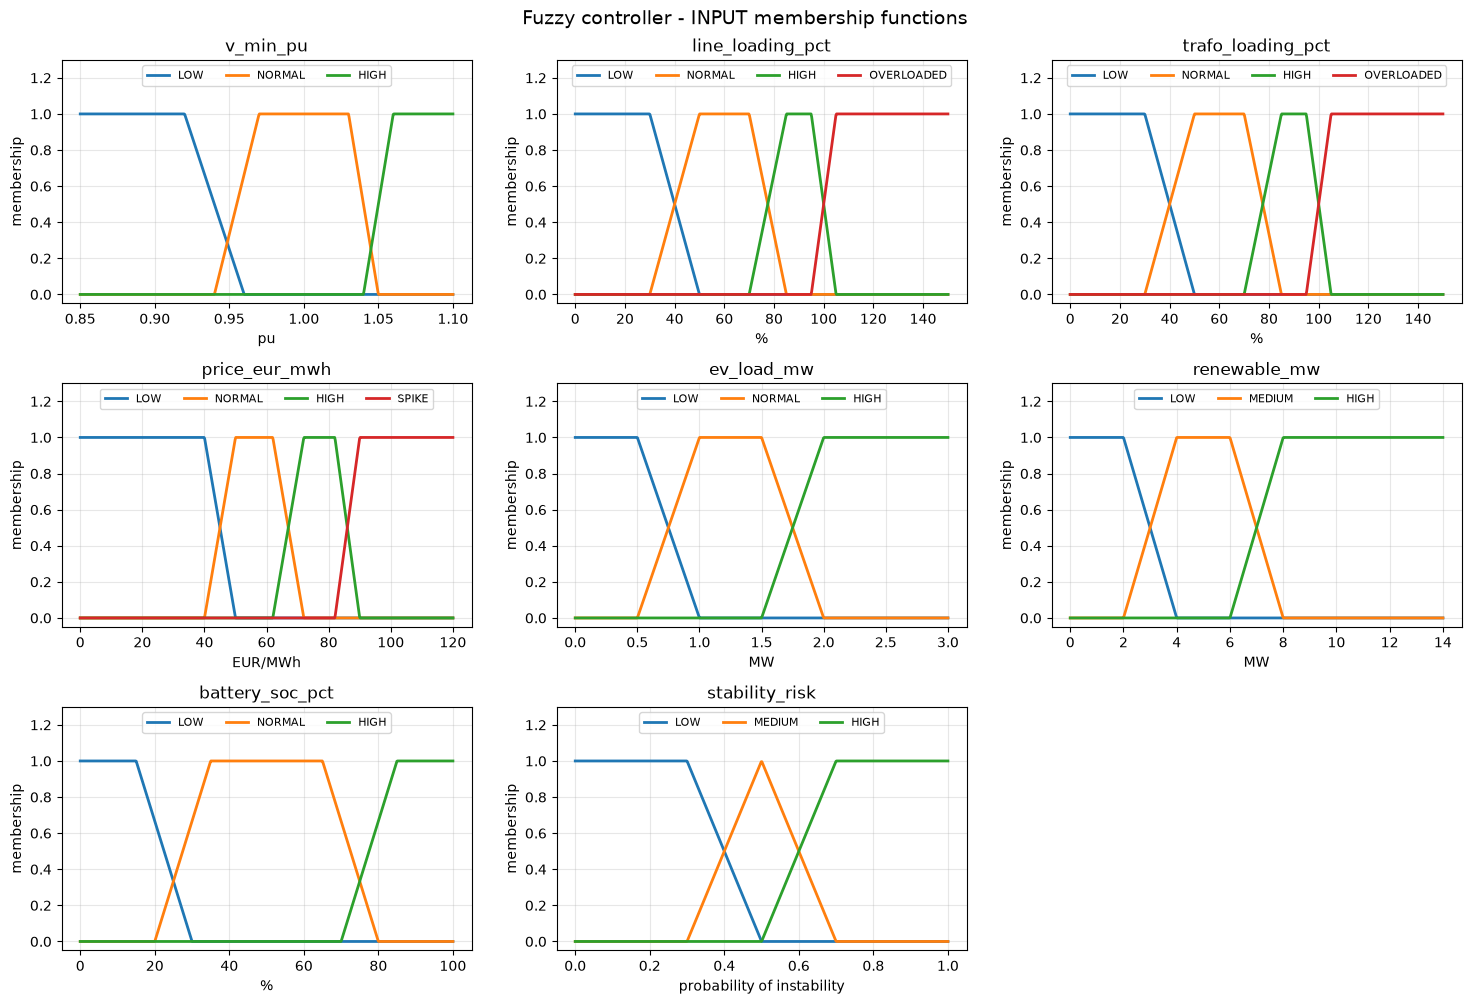

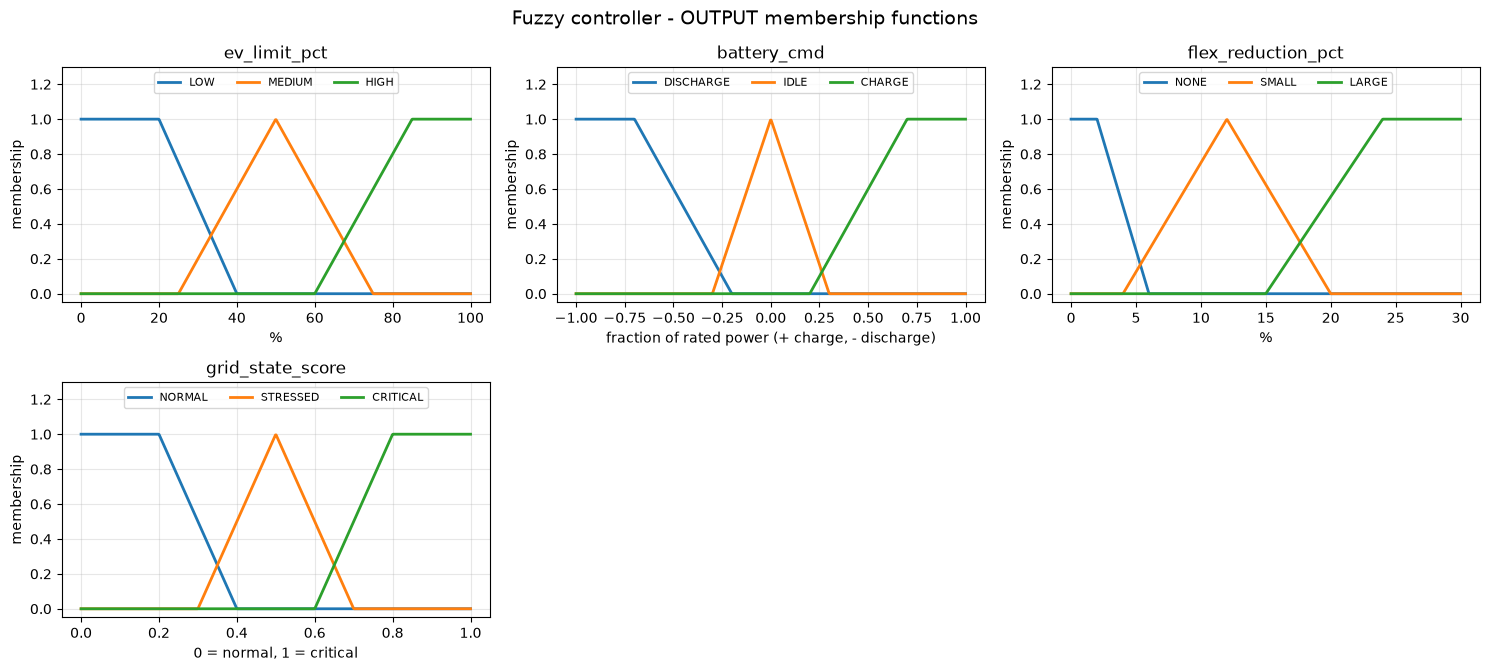

In [4]:
def plot_variables(table, title, filename):
    n = len(table)
    cols = 3
    rows = int(np.ceil(n / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(15, 3.4 * rows))
    axes = np.atleast_1d(axes).ravel()
    for ax, (name, var) in zip(axes, table.items()):
        lo, hi = var["range"]
        x = np.linspace(lo, hi, 600)
        for label, params in var["sets"].items():
            ax.plot(x, trapmf(x, params), linewidth=2, label=label)
        ax.set_title(name)
        ax.set_xlabel(var["unit"])
        ax.set_ylabel("membership")
        ax.set_ylim(-0.05, 1.3)
        ax.grid(alpha=0.3)
        ax.legend(fontsize=8, loc="upper center", ncol=len(var["sets"]))
    for ax in axes[n:]:
        ax.axis("off")
    fig.suptitle(title, fontsize=14)
    fig.tight_layout()
    fig.savefig(filename, dpi=150)
    plt.show()


plot_variables(INPUTS, "Fuzzy controller - INPUT membership functions",
               "output/fuzzy_input_membership.png")
plot_variables(OUTPUTS, "Fuzzy controller - OUTPUT membership functions",
               "output/fuzzy_output_membership.png")

### Design notes (for the viva)

- **Voltage:** the 0.95 pu limit sits inside the overlap of LOW and NORMAL, so a reading just below the limit is mostly LOW. HIGH (over-voltage) matters mainly when PV is high and the battery is charging.
- **Loading:** HIGH starts at 70 % and OVERLOADED at 95 %, so the controller acts before 100 % is reached.
- **Price:** thresholds follow the training price distribution (median about 55, 90th percentile about 73, 99th percentile about 89 EUR/MWh).
- **Battery SOC:** LOW and HIGH start inside the 10 - 90 % limits so the controller does not push the battery against its physical limits.
- **Battery command sign:** positive = charge, negative = discharge, same as pandapower `storage.p_mw` and `sarvesh_lib.py`.

**Next:** Step 3 below, the rule base.

## Step 3 - Rule base

The rules are Mamdani-style: `IF <conditions> THEN <output sets>`. `AND` uses the minimum, `OR` the maximum and `NOT` the complement (1 - degree). `SUM` (bounded sum, capped at 1) joins neighbouring sets such as HIGH + OVERLOADED, so there is no false dip where their curves cross. A rule can set several outputs at once.

Two reusable conditions keep the rule base short:

- **STRESS** = voltage LOW, or line loading HIGH/OVERLOADED, or transformer loading HIGH/OVERLOADED.
- **HEALTHY** = NOT STRESS (no sign of stress at all).
- **CRITICAL** = any line/transformer OVERLOADED, or low voltage together with HIGH loading. The "stressed" rules use NOT CRITICAL, so a critical grid is not also reported as merely stressed.

Rules are grouped by situation:

| Group | Situation | Main action |
|---|---|---|
| A | Critical / stressed grid | cut EV charging, reduce flexible load, discharge battery |
| B | Preventive EV control | trim EV charging before the grid is stressed |
| C | High price or price spike | discharge battery, shift EV charging, small demand response |
| D | Normal operation | full EV charging, battery idle, no load reduction |
| E | Renewable surplus / over-voltage | charge battery, allow full EV charging |
| F | Battery protection | never discharge a low battery |

In [5]:
# ---- Rule language -------------------------------------------------------
def IS(var, label):  return ("IS", var, label)
def AND(*terms):     return ("AND", terms)
def OR(*terms):      return ("OR", terms)
def NOT(term):       return ("NOT", term)
def SUM(*terms):     return ("SUM", terms)   # bounded sum: union of neighbouring sets without a dip where they cross

STRESS = OR(
    IS("v_min_pu", "LOW"),
    SUM(IS("line_loading_pct", "HIGH"), IS("line_loading_pct", "OVERLOADED")),
    SUM(IS("trafo_loading_pct", "HIGH"), IS("trafo_loading_pct", "OVERLOADED")),
)
HEALTHY      = NOT(STRESS)                                   # no stress sign at all
SOC_OK       = NOT(IS("battery_soc_pct", "LOW"))             # battery can discharge
SOC_ROOM     = NOT(IS("battery_soc_pct", "HIGH"))            # battery can charge
PRICE_HIGH   = SUM(IS("price_eur_mwh", "HIGH"), IS("price_eur_mwh", "SPIKE"))
PRICE_CHEAP  = NOT(PRICE_HIGH)
STABILITY_HIGH = IS("stability_risk", "HIGH")
ANY_OVERLOAD = OR(IS("line_loading_pct", "OVERLOADED"), IS("trafo_loading_pct", "OVERLOADED"))
LOWV_AND_HIGH_LOAD = AND(IS("v_min_pu", "LOW"), OR(IS("line_loading_pct", "HIGH"), IS("trafo_loading_pct", "HIGH")))
CRITICAL     = OR(ANY_OVERLOAD, LOWV_AND_HIGH_LOAD)          # NOT(CRITICAL) keeps the stressed rules exclusive

# ---- Rule base: (id, group, condition, outputs, weight) ---------------------
RULES = [
    # A. Critical / stressed grid
    ("A1", "A", ANY_OVERLOAD,
        dict(ev_limit_pct="LOW", flex_reduction_pct="LARGE", grid_state_score="CRITICAL"), 1.0),
    ("A2", "A", LOWV_AND_HIGH_LOAD,
        dict(ev_limit_pct="LOW", flex_reduction_pct="LARGE", grid_state_score="CRITICAL"), 1.0),
    ("A3", "A", AND(IS("v_min_pu", "LOW"), NOT(CRITICAL)),
        dict(ev_limit_pct="LOW", flex_reduction_pct="SMALL", grid_state_score="STRESSED"), 1.0),
    ("A4", "A", AND(IS("line_loading_pct", "HIGH"), NOT(CRITICAL)),
        dict(ev_limit_pct="MEDIUM", flex_reduction_pct="SMALL", grid_state_score="STRESSED"), 1.0),
    ("A5", "A", AND(IS("trafo_loading_pct", "HIGH"), NOT(CRITICAL)),
        dict(ev_limit_pct="MEDIUM", flex_reduction_pct="SMALL", grid_state_score="STRESSED"), 1.0),
    ("A6", "A", AND(IS("ev_load_mw", "HIGH"), OR(IS("line_loading_pct", "HIGH"), IS("trafo_loading_pct", "HIGH"))),
        dict(ev_limit_pct="LOW"), 1.0),
    ("A7", "A", AND(STRESS, SOC_OK),
        dict(battery_cmd="DISCHARGE"), 1.0),

    # B. Preventive EV control (grid still healthy)
    ("B1", "B", AND(HEALTHY, IS("ev_load_mw", "HIGH"), OR(IS("line_loading_pct", "NORMAL"), IS("trafo_loading_pct", "NORMAL"))),
        dict(ev_limit_pct="MEDIUM"), 0.8),

    # C. High price / price spike
    ("C1", "C", AND(PRICE_HIGH, SOC_OK),
        dict(battery_cmd="DISCHARGE"), 1.0),
    ("C2", "C", IS("price_eur_mwh", "SPIKE"),
        dict(ev_limit_pct="MEDIUM", flex_reduction_pct="SMALL"), 1.0),
    ("C3", "C", AND(IS("price_eur_mwh", "HIGH"), IS("ev_load_mw", "HIGH")),
        dict(ev_limit_pct="MEDIUM"), 0.8),
    ("C4", "C", AND(IS("price_eur_mwh", "HIGH"), HEALTHY),
        dict(flex_reduction_pct="SMALL"), 0.6),

    # D. Normal operation
    ("D1", "D", AND(HEALTHY, PRICE_CHEAP, NOT(STABILITY_HIGH)),
        dict(ev_limit_pct="HIGH", flex_reduction_pct="NONE", grid_state_score="NORMAL"), 1.0),
    ("D2", "D", AND(HEALTHY, IS("price_eur_mwh", "NORMAL"), IS("battery_soc_pct", "NORMAL")),
        dict(battery_cmd="IDLE"), 1.0),
    ("D3", "D", AND(HEALTHY, IS("price_eur_mwh", "LOW"), SOC_ROOM),
        dict(battery_cmd="CHARGE"), 1.0),
    ("D4", "D", AND(HEALTHY, IS("price_eur_mwh", "NORMAL"), IS("battery_soc_pct", "LOW")),
        dict(battery_cmd="CHARGE"), 0.8),
    ("D5", "D", AND(HEALTHY, PRICE_HIGH, NOT(STABILITY_HIGH)),
        dict(grid_state_score="NORMAL"), 1.0),
    ("D6", "D", AND(HEALTHY, IS("battery_soc_pct", "HIGH"), PRICE_CHEAP),
        dict(battery_cmd="IDLE"), 1.0),

    # E. Renewable surplus / over-voltage
    ("E1", "E", AND(IS("renewable_mw", "HIGH"), HEALTHY, SOC_ROOM),
        dict(battery_cmd="CHARGE", ev_limit_pct="HIGH", flex_reduction_pct="NONE"), 1.0),
    ("E2", "E", AND(IS("v_min_pu", "HIGH"), SOC_ROOM),
        dict(battery_cmd="CHARGE", ev_limit_pct="HIGH"), 1.0),
    ("E3", "E", AND(IS("v_min_pu", "HIGH"), IS("battery_soc_pct", "HIGH")),
        dict(battery_cmd="IDLE", ev_limit_pct="HIGH"), 1.0),
    ("E4", "E", AND(IS("renewable_mw", "HIGH"), IS("battery_soc_pct", "HIGH"), HEALTHY),
        dict(battery_cmd="IDLE", ev_limit_pct="HIGH"), 1.0),

    # F. Battery protection
    ("F1", "F", AND(STRESS, IS("battery_soc_pct", "LOW")),
        dict(battery_cmd="IDLE"), 1.0),
    ("F2", "F", AND(PRICE_HIGH, IS("battery_soc_pct", "LOW")),
        dict(battery_cmd="IDLE"), 1.0),

    ("G1", "G", AND(STABILITY_HIGH, STRESS),
        dict(ev_limit_pct="LOW", flex_reduction_pct="LARGE",grid_state_score="CRITICAL"), 0.8),

    ("G2", "G", AND(STABILITY_HIGH, HEALTHY),
        dict(ev_limit_pct="MEDIUM",grid_state_score="STRESSED"), 0.7),
]

In [6]:
# ---- Rule evaluation ---------------------------------------------------------
def eval_condition(node, mu):
    kind = node[0]
    if kind == "IS":
        return mu[node[1]][node[2]]
    if kind == "NOT":
        return 1.0 - eval_condition(node[1], mu)
    values = [eval_condition(t, mu) for t in node[1]]
    if kind == "AND":
        return min(values)
    if kind == "SUM":
        return min(1.0, sum(values))
    return max(values)


def fuzzify_state(state):
    return {name: fuzzify(INPUTS, name, state[name]) for name in INPUTS}


def fire_rules(state):
    """Firing strength of every rule for one grid state (dict of the 8 inputs)."""
    mu = fuzzify_state(state)
    return [(rid, grp, weight * eval_condition(cond, mu), outs)
            for rid, grp, cond, outs, weight in RULES]


def output_activation(fired):
    """Max-aggregate rule strengths per output set (the input to defuzzification, Step 4)."""
    act = {o: {s: 0.0 for s in OUTPUTS[o]["sets"]} for o in OUTPUTS}
    for rid, grp, strength, outs in fired:
        for o, label in outs.items():
            act[o][label] = max(act[o][label], strength)
    return act

In [7]:
# ---- Rule-base checks and documentation ---------------------------------------
def condition_text(node):
    kind = node[0]
    if kind == "IS":
        return f"{node[1]} is {node[2]}"
    if kind == "NOT":
        return "NOT " + condition_text(node[1])
    joiner = " + " if kind == "SUM" else f" {kind} "
    return "(" + joiner.join(condition_text(t) for t in node[1]) + ")"

# Check 1: every referenced variable/set exists
def check_refs(node):
    if node[0] == "IS":
        assert node[2] in INPUTS[node[1]]["sets"], f"Unknown set: {node}"
    elif node[0] == "NOT":
        check_refs(node[1])
    else:
        for t in node[1]:
            check_refs(t)

used_outputs = {o: set() for o in OUTPUTS}
for rid, grp, cond, outs, w in RULES:
    check_refs(cond)
    for o, label in outs.items():
        assert label in OUTPUTS[o]["sets"], f"Unknown output set in {rid}: {o}={label}"
        used_outputs[o].add(label)

# Check 2: every output set is produced by at least one rule
for o, sets in OUTPUTS.items():
    missing = set(sets["sets"]) - used_outputs[o]
    assert not missing, f"Output sets never used: {o} {missing}"

print(f"Rule base OK: {len(RULES)} rules, all references valid, every output set is used.\n")

import pandas as pd
rule_table = pd.DataFrame([
    {"rule": rid, "group": grp, "weight": w,
     "IF": condition_text(cond),
     "THEN": ", ".join(f"{o} = {l}" for o, l in outs.items())}
    for rid, grp, cond, outs, w in RULES
])
rule_table.to_csv("output/fuzzy_rule_base.csv", index=False)
print(rule_table.groupby("group").size().rename("rules per group").to_string())

Rule base OK: 26 rules, all references valid, every output set is used.

group
A    7
B    1
C    4
D    6
E    4
F    2
G    2


### Test: which rules fire for realistic grid states

These states are taken from the project results (annual peak, 4x load stress, EV overload) plus three typical operating conditions. For each one, the table shows the strongest activation of each output set, which is exactly what Step 4 will defuzzify into numbers.

In [10]:

TEST_STATES = {
    "1 Normal day": dict(v_min_pu=.99, line_loading_pct=32, trafo_loading_pct=31,
        price_eur_mwh=60, ev_load_mw=.8, renewable_mw=3, battery_soc_pct=50, stability_risk=.10),

    "2 4x load stress": dict(v_min_pu=.858, line_loading_pct=143, trafo_loading_pct=139,
        price_eur_mwh=72, ev_load_mw=0, renewable_mw=.3, battery_soc_pct=50, stability_risk=.90),

    "3 EV overload": dict(v_min_pu=.92, line_loading_pct=110, trafo_loading_pct=98,
        price_eur_mwh=65, ev_load_mw=2.5, renewable_mw=1, battery_soc_pct=60, stability_risk=.80),

        "4 Price spike, healthy": dict(v_min_pu=.99, line_loading_pct=40, trafo_loading_pct=35,
        price_eur_mwh=95, ev_load_mw=1.2, renewable_mw=1, battery_soc_pct=70, stability_risk=.10),

    "5 PV surplus": dict(v_min_pu=1.045, line_loading_pct=45, trafo_loading_pct=40,
        price_eur_mwh=45, ev_load_mw=.5, renewable_mw=10, battery_soc_pct=30, stability_risk=.10),

    "6 Stress, battery low": dict(v_min_pu=.96, line_loading_pct=88, trafo_loading_pct=80,
        price_eur_mwh=70, ev_load_mw=1.8, renewable_mw=.5, battery_soc_pct=12, stability_risk=.40),
    
}

rows = []
for name, state in TEST_STATES.items():
    fired = fire_rules(state)
    act = output_activation(fired)
    row = {"state": name}
    for o in OUTPUTS:
        best = max(act[o], key=act[o].get)
        row[o] = f"{best} ({act[o][best]:.2f})"
    row["rules fired"] = ", ".join(r[0] for r in fired if r[2] > 0.05)
    rows.append(row)

pd.set_option("display.width", 250, "display.max_colwidth", 80)
result = pd.DataFrame(rows).set_index("state")
print(result.drop(columns="rules fired").to_string())


                         ev_limit_pct       battery_cmd flex_reduction_pct grid_state_score
state                                                                                      
1 Normal day              HIGH (1.00)       IDLE (1.00)        NONE (1.00)    NORMAL (1.00)
2 4x load stress           LOW (1.00)  DISCHARGE (1.00)       LARGE (1.00)  CRITICAL (1.00)
3 EV overload              LOW (1.00)  DISCHARGE (1.00)       LARGE (1.00)  CRITICAL (1.00)
4 Price spike, healthy  MEDIUM (1.00)  DISCHARGE (1.00)       SMALL (1.00)    NORMAL (1.00)
5 PV surplus              HIGH (1.00)     CHARGE (1.00)        NONE (1.00)    NORMAL (1.00)
6 Stress, battery low   MEDIUM (1.00)       IDLE (1.00)       SMALL (1.00)  STRESSED (1.00)


In [11]:
# Behaviour checks: the rule base must react the way the project expects
def top(state, out):
    act = output_activation(fire_rules(TEST_STATES[state]))[out]
    return max(act, key=act.get)

assert top("2 4x load stress", "grid_state_score") == "CRITICAL"
assert top("2 4x load stress", "ev_limit_pct") == "LOW"
assert top("2 4x load stress", "flex_reduction_pct") == "LARGE"
assert top("2 4x load stress", "battery_cmd") == "DISCHARGE"
assert top("1 Normal day", "grid_state_score") == "NORMAL"
assert top("1 Normal day", "ev_limit_pct") == "HIGH"
assert top("3 EV overload", "ev_limit_pct") == "LOW"
assert top("3 EV overload", "grid_state_score") == "CRITICAL"
assert top("6 Stress, battery low", "grid_state_score") == "STRESSED"
assert top("4 Price spike, healthy", "battery_cmd") == "DISCHARGE"
assert top("5 PV surplus", "battery_cmd") == "CHARGE"
assert top("6 Stress, battery low", "battery_cmd") == "IDLE"   # battery protection
print("All behaviour checks passed.")

All behaviour checks passed.


### Design notes (for the viva)

- **Why group rules?** Each group matches one situation in the project brief: stressed grid, normal operation, high price and renewable surplus. Groups B and F are safety additions (preventive EV trimming, battery protection).
- **Grid safety beats price.** Group A rules have weight 1.0 and reduce EV charging even when the price is low. Price rules only get full freedom when the grid is HEALTHY.
- **Battery protection (F1, F2):** a battery below about 20 % SOC is never told to discharge, so it stays inside Sarvesh's 10 - 90 % limits.
- **Over-voltage (E2, E3):** when PV pushes voltage HIGH, the battery absorbs power and EV charging is allowed, which pulls the voltage down.
- **Rule base is data, not code.** `output/fuzzy_rule_base.csv` is the documentation deliverable ("documented membership functions and rule base").

**Next:** Step 4 below, defuzzification.

## Step 4 - Defuzzification

Step 3 ends with an activation level for every output set. Defuzzification turns them into one number per output:

1. **Clip** each output set at its activation level (Mamdani minimum).
2. **Aggregate** the clipped sets with the maximum.
3. **Centroid** of the aggregated shape gives the crisp value.

**Calibration.** A plain centroid never reaches the ends of the range (a fully active HIGH set gives about 93 %, not 100 %), so a healthy grid would still lose some EV charging. The centroid is therefore rescaled linearly so that the lowest and highest sets of each output map exactly to the ends of its **command range**:

| Output | Command range | Why |
|---|---|---|
| `ev_limit_pct` | 10 - 100 % | never fully stop EV charging (cars with an early departure still get some energy) |
| `battery_cmd` | -1 to +1 | full discharge to full charge, idle = 0 |
| `flex_reduction_pct` | 0 - 30 % | maximum demand-response cut |
| `grid_state_score` | 0 - 1 | mapped to NORMAL / STRESSED / CRITICAL |

In [13]:
N_POINTS = 1001

# (lowest set, highest set) of each output, and the command range they map to
CALIBRATION = {
    "ev_limit_pct":       ("LOW",       "HIGH",     (10.0, 100.0)),
    "battery_cmd":        ("DISCHARGE", "CHARGE",   (-1.0, 1.0)),
    "flex_reduction_pct": ("NONE",      "LARGE",    (0.0, 30.0)),
    "grid_state_score":   ("NORMAL",    "CRITICAL", (0.0, 1.0)),
}
DEFAULTS = {   # used only if no rule at all fires for an output
    "ev_limit_pct": 100.0, "battery_cmd": 0.0, "flex_reduction_pct": 0.0, "grid_state_score": 0.0,
}


def raw_centroid(name, activation):
    """Clip -> aggregate (max) -> centroid for one output. Returns None if nothing is active."""
    lo, hi = OUTPUTS[name]["range"]
    x = np.linspace(lo, hi, N_POINTS)
    shape = np.zeros_like(x)
    for label, level in activation.items():
        if level > 0:
            clipped = np.minimum(level, trapmf(x, OUTPUTS[name]["sets"][label]))
            shape = np.maximum(shape, clipped)
    area = shape.sum()
    return None if area < 1e-9 else float((x * shape).sum() / area)


# Centroid of the lowest / highest set at full strength (the calibration anchors)
ANCHORS = {}
for _name, (_lo_set, _hi_set, _rng) in CALIBRATION.items():
    ANCHORS[_name] = (
        raw_centroid(_name, {_lo_set: 1.0}),
        raw_centroid(_name, {_hi_set: 1.0}),
    )


def defuzzify(name, activation):
    c = raw_centroid(name, activation)
    if c is None:
        return DEFAULTS[name]
    c_lo, c_hi = ANCHORS[name]
    out_lo, out_hi = CALIBRATION[name][2]
    value = out_lo + (c - c_lo) / (c_hi - c_lo) * (out_hi - out_lo)
    return float(np.clip(value, out_lo, out_hi))


def grid_state_label(score):
    memberships = fuzzify(OUTPUTS, "grid_state_score", score)
    return max(memberships, key=memberships.get)


def fuzzy_infer(state):
    """Full pipeline for one grid state: fuzzify -> rules -> defuzzify."""
    act = output_activation(fire_rules(state))
    crisp = {name: defuzzify(name, act[name]) for name in OUTPUTS}
    crisp["grid_state"] = grid_state_label(crisp["grid_state_score"])
    return crisp


print("Calibration anchors (raw centroid of the lowest / highest set):")
for n, (a, b) in ANCHORS.items():
    print(f"  {n:20s} {a:8.3f} -> {b:8.3f}")

Calibration anchors (raw centroid of the lowest / highest set):
  ev_limit_pct           15.530 ->   85.330
  battery_cmd            -0.707 ->    0.707
  flex_reduction_pct      2.159 ->   24.437
  grid_state_score        0.155 ->    0.845


### Test 1 - the six grid states from Step 3

Same states as before, now with numerical commands. `battery_mw` assumes the 5 MW battery from Sarvesh's `battery_config.json`.

In [14]:
BATTERY_RATED_MW = 5.0   # from output/battery_config.json (p_max_mw)

rows = []
for name, state in TEST_STATES.items():
    r = fuzzy_infer(state)
    rows.append({
        "state": name,
        "grid_state": r["grid_state"],
        "score": round(r["grid_state_score"], 2),
        "ev_limit_%": round(r["ev_limit_pct"], 1),
        "battery_cmd": round(r["battery_cmd"], 2),
        "battery_MW": round(r["battery_cmd"] * BATTERY_RATED_MW, 2),
        "flex_cut_%": round(r["flex_reduction_pct"], 1),
    })
commands = pd.DataFrame(rows).set_index("state")
print(commands.to_string())

                       grid_state  score  ev_limit_%  battery_cmd  battery_MW  flex_cut_%
state                                                                                    
1 Normal day               NORMAL    0.0       100.0         0.00        0.00         0.0
2 4x load stress         CRITICAL    1.0        10.0        -1.00       -5.00        30.0
3 EV overload            CRITICAL    1.0        20.9        -1.00       -5.00        30.0
4 Price spike, healthy     NORMAL    0.0        54.4        -1.00       -5.00        13.3
5 PV surplus               NORMAL    0.0       100.0         0.71        3.56         0.0
6 Stress, battery low    STRESSED    0.5        35.6         0.00        0.00        13.3


In [15]:
# Checks on the crisp numbers
def cmd(state): return fuzzy_infer(TEST_STATES[state])

assert cmd("1 Normal day")["ev_limit_pct"] > 95            # healthy grid: (almost) no EV limit
assert cmd("1 Normal day")["flex_reduction_pct"] < 2       # and no load cut
assert abs(cmd("1 Normal day")["battery_cmd"]) < 0.1       # battery idle
assert cmd("2 4x load stress")["ev_limit_pct"] < 20        # critical: EVs heavily limited
assert cmd("2 4x load stress")["flex_reduction_pct"] > 25  # maximum load cut
assert cmd("2 4x load stress")["battery_cmd"] < -0.9       # full discharge
assert cmd("2 4x load stress")["grid_state"] == "CRITICAL"
assert cmd("4 Price spike, healthy")["battery_cmd"] < -0.9
assert cmd("5 PV surplus")["battery_cmd"] > 0.5          # charges (price is on the LOW/NORMAL border, so not full power)
assert abs(cmd("6 Stress, battery low")["battery_cmd"]) < 0.1   # protected battery stays idle
assert cmd("6 Stress, battery low")["grid_state"] == "STRESSED"
print("All crisp-output checks passed.")

All crisp-output checks passed.


In [16]:
risk_state = dict(TEST_STATES["1 Normal day"])  # Start with a healthy grid state.
risk_state["stability_risk"] = 0.90             # Change only the ML risk input.

risk_result = fuzzy_infer(risk_state)            # Run full fuzzy inference.

print("Healthy grid + high ML risk:")
print(risk_result)

assert risk_result["grid_state"] == "STRESSED"
print("High stability-risk supporting-rule check passed.")

Healthy grid + high ML risk:
{'ev_limit_pct': 54.44595873451707, 'battery_cmd': 0.0, 'flex_reduction_pct': 0.0, 'grid_state_score': 0.49999999999999994, 'grid_state': 'STRESSED'}
High stability-risk supporting-rule check passed.


### Test 2 - response curves

One input is swept while the others stay at a normal operating point. Smooth curves show the controller does not jump between commands.

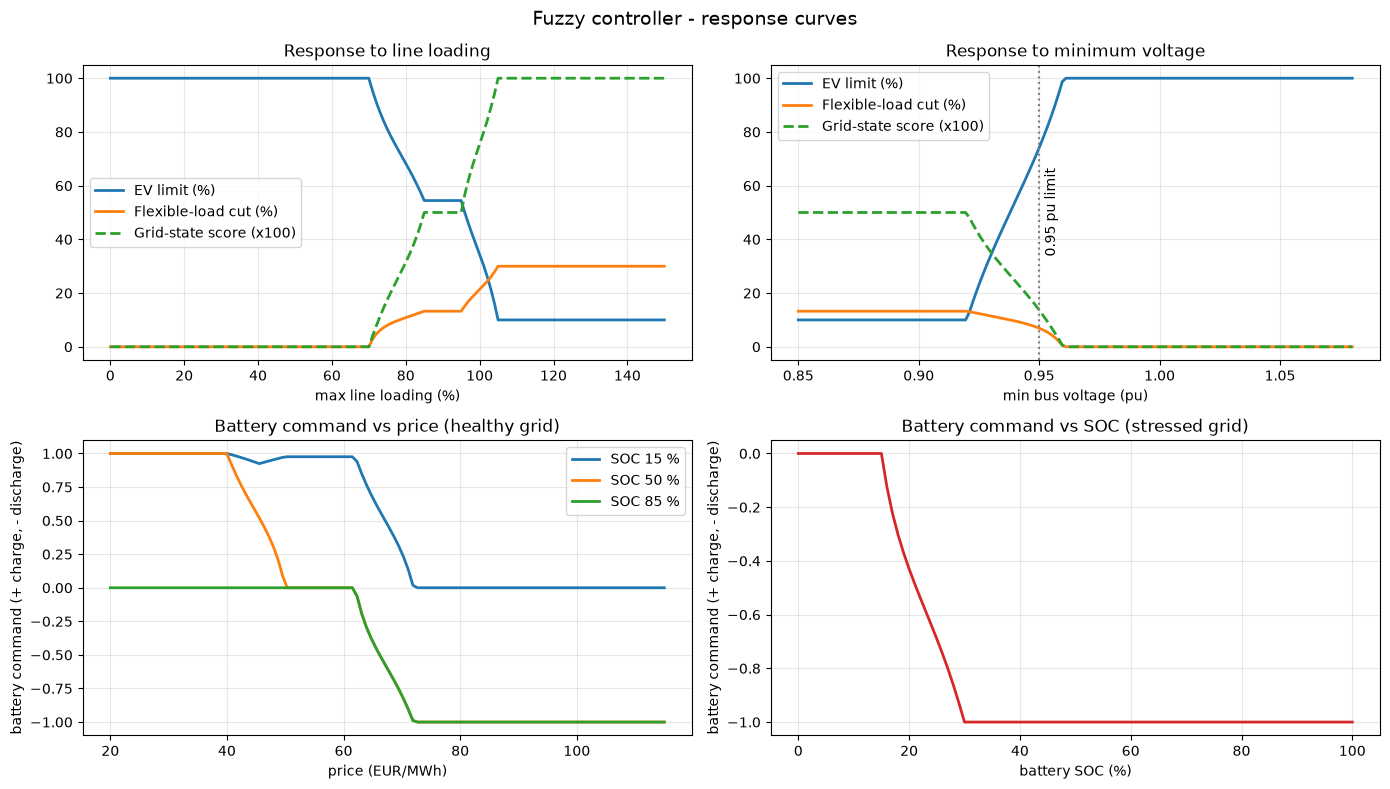

Response-curve checks passed.


In [18]:
BASE = dict(
    v_min_pu=0.99,
    line_loading_pct=35,
    trafo_loading_pct=35,
    price_eur_mwh=55,
    ev_load_mw=0.8,
    renewable_mw=3.0,
    battery_soc_pct=60,
    stability_risk=0.10,  # Healthy baseline ML risk for response sweeps.
)

def sweep(var, values, **fixed):
    out = []
    for v in values:
        state = {**BASE, **fixed, var: v}
        out.append(fuzzy_infer(state))
    return out

fig, axes = plt.subplots(2, 2, figsize=(14, 8))

# (a) line loading -> EV limit, flexible-load cut, state score
x = np.linspace(0, 150, 151)
r = sweep("line_loading_pct", x)
ax = axes[0, 0]
ax.plot(x, [q["ev_limit_pct"] for q in r], label="EV limit (%)", linewidth=2)
ax.plot(x, [q["flex_reduction_pct"] for q in r], label="Flexible-load cut (%)", linewidth=2)
ax.plot(x, [q["grid_state_score"] * 100 for q in r], "--", label="Grid-state score (x100)", linewidth=2)
ax.set_title("Response to line loading"); ax.set_xlabel("max line loading (%)")
ax.legend(); ax.grid(alpha=0.3)
assert r[30]["ev_limit_pct"] > r[120]["ev_limit_pct"] + 50

# (b) minimum voltage -> same outputs
x = np.linspace(0.85, 1.08, 150)
r = sweep("v_min_pu", x)
ax = axes[0, 1]
ax.plot(x, [q["ev_limit_pct"] for q in r], label="EV limit (%)", linewidth=2)
ax.plot(x, [q["flex_reduction_pct"] for q in r], label="Flexible-load cut (%)", linewidth=2)
ax.plot(x, [q["grid_state_score"] * 100 for q in r], "--", label="Grid-state score (x100)", linewidth=2)
ax.axvline(0.95, color="grey", linestyle=":"); ax.text(0.952, 50, "0.95 pu limit", rotation=90, va="center")
ax.set_title("Response to minimum voltage"); ax.set_xlabel("min bus voltage (pu)")
ax.legend(); ax.grid(alpha=0.3)

# (c) price -> battery command (healthy grid) for three SOC levels
x = np.linspace(20, 115, 120)
ax = axes[1, 0]
for soc in (15, 50, 85):
    r = sweep("price_eur_mwh", x, battery_soc_pct=soc)
    ax.plot(x, [q["battery_cmd"] for q in r], label=f"SOC {soc} %", linewidth=2)
ax.set_title("Battery command vs price (healthy grid)")
ax.set_xlabel("price (EUR/MWh)"); ax.set_ylabel("battery command (+ charge, - discharge)")
ax.legend(); ax.grid(alpha=0.3)

# (d) battery SOC -> battery command in a stressed grid
x = np.linspace(0, 100, 101)
r = sweep("battery_soc_pct", x, line_loading_pct=110, v_min_pu=0.93)
ax = axes[1, 1]
ax.plot(x, [q["battery_cmd"] for q in r], linewidth=2, color="tab:red")
ax.set_title("Battery command vs SOC (stressed grid)")
ax.set_xlabel("battery SOC (%)"); ax.set_ylabel("battery command (+ charge, - discharge)")
ax.grid(alpha=0.3)
assert r[5]["battery_cmd"] > r[60]["battery_cmd"] + 0.5   # low battery is protected

fig.suptitle("Fuzzy controller - response curves", fontsize=14)
fig.tight_layout()
fig.savefig("output/fuzzy_response_curves.png", dpi=150)
plt.show()
print("Response-curve checks passed.")

### Design notes (for the viva)

- **Method:** Mamdani inference (min for AND/clipping, max for OR/aggregation) with centroid defuzzification, a standard textbook choice.
- **Calibration:** the centroid is rescaled so full-strength LOW/HIGH sets reach the ends of the command range. Without it a healthy grid would still lose about 7 % of EV charging.
- **EV floor of 10 %:** even a critical grid never receives a hard stop, which protects EV users with early departures.
- **Smooth output:** the response curves show gradual changes, so commands do not flip abruptly between time steps.
- **Battery sign:** positive = charge, negative = discharge. Multiply `battery_cmd` by the rated power (5 MW) to get the MW set-point.

**Next:** Step 5 below, the controller function.

## Step 5 - Controller function (common interface)

One function, `fuzzy_controller(grid_state, ...)`, is all the other modules need to call.

**Input** `grid_state`: a dict with the seven inputs. Names used by `sarvesh_lib.grid_metrics()` and by Sujit's `run_grid()` are accepted too (`max_line_loading_pct` / `max_line_pct`, and so on).

**Output** (dict):

| Key | Meaning | Used by |
|---|---|---|
| `ev_limit_pct`, `ev_factor` | EV charging cap (% and 0-1 multiplier) | multiply every EV bus load |
| `battery_mw` | final battery set-point, **+ charge / - discharge**, repaired for SOC and power limits | `set_battery_power()` |
| `battery_source` | `"fuzzy"` or `"pso"` | logging |
| `flex_reduction_pct`, `flex_factor` | demand-response cut and load multiplier | multiply the flexible part of the loads |
| `grid_state`, `grid_state_score` | NORMAL / STRESSED / CRITICAL and its 0-1 score | dashboard, ESP32 |
| `fallback` | True if the power flow failed or the input was invalid | safety |

**Design decisions**

- **Battery arbitration:** the PSO schedule is the day-ahead plan. Fuzzy logic overrides it only when `grid_state_score >= BATTERY_OVERRIDE_SCORE` (default 0.25), i.e. when the grid actually needs help. This keeps PSO (planning) and fuzzy (reacting) separate, as the project brief requires.
- **Flexible load:** `flex_factor = 1 - FLEX_SHARE * reduction / 100`. `FLEX_SHARE` is the part of demand that is controllable. **It is an assumption (30 %) that the team should confirm.**
- **Safe fallback:** if the power flow did not converge or an input is missing, the controller returns a conservative command instead of crashing.

In [19]:
import math

try:
    from sarvesh_lib import BatteryConfig, battery_dispatch, set_battery_power   # Sarvesh's battery model
except ImportError:
    BatteryConfig = battery_dispatch = set_battery_power = None
    print("sarvesh_lib.py not found next to this notebook: battery limits will not be repaired.")

BATTERY_RATED_MW = 5.0            # output/battery_config.json
BATTERY_OVERRIDE_SCORE = 0.25     # fuzzy overrides PSO only above this grid-state score (0 = always fuzzy)
FLEX_SHARE = 0.30                 # ASSUMPTION: share of demand that is flexible (confirm with the team)

FALLBACK = dict(ev_limit_pct=50.0, battery_cmd=0.0, flex_reduction_pct=10.0,
                grid_state_score=1.0, grid_state="CRITICAL")

KEY_ALIASES = {
    "v_min_pu":          ["v_min_pu"],
    "line_loading_pct":  ["line_loading_pct", "max_line_loading_pct", "max_line_pct"],
    "trafo_loading_pct": ["trafo_loading_pct", "max_trafo_loading_pct", "max_trafo_pct"],
    "price_eur_mwh":     ["price_eur_mwh", "price_forecast", "price"],
    "ev_load_mw":        ["ev_load_mw"],
    "renewable_mw":      ["renewable_mw"],
    "battery_soc_pct":   ["battery_soc_pct", "battery_soc"],
    "stability_risk":    ["stability_risk","instability_probability","stability_probability",],
}


def build_grid_state(source=None, **overrides):
    """Collect the seven controller inputs from any dict-like (power-flow metrics, a dataframe row, ...).
    Extra keyword arguments win over `source`. Returns None if an input is missing or not a number.
    Battery SOC given as a fraction (0-1) is converted to percent."""
    merged = {**(dict(source) if source is not None else {}), **overrides}
    state = {}
    for name, aliases in KEY_ALIASES.items():
        value = next((merged[a] for a in aliases if a in merged), None)
        if value is None or not np.isfinite(float(value)):
            return None
        state[name] = float(value)
    if state["battery_soc_pct"] <= 1.0:
        state["battery_soc_pct"] *= 100.0
    for name, var in INPUTS.items():          # keep inside the universe of each variable
        lo, hi = var["range"]
        state[name] = float(np.clip(state[name], lo, hi))
    return state

def choose_dr_action(state, result):
    """Map fuzzy outputs to the final project-level demand-response action."""
    if result["grid_state"] == "CRITICAL":
        return "LOAD SHED"
    if result["grid_state"] == "STRESSED":
        return "LOAD DEFER"

    economic_control = (
        result["ev_limit_pct"] < 95.0
        or result["flex_reduction_pct"] > 2.0
    )

    if state["price_eur_mwh"] >= 72.0 and economic_control:
        return "LOAD SHIFT"

    return "NO ACTION"

def fuzzy_controller(grid_state, pso_battery_mw=None, battery_cfg=None, battery_energy_mwh=None,
                     battery_rated_mw=BATTERY_RATED_MW):
    """Real-time supervisory controller.

    grid_state          dict with the 7 inputs (or None / invalid -> safe fallback)
    pso_battery_mw      PSO day-ahead battery set-point for this step (MW, + charge), optional
    battery_cfg         sarvesh_lib.BatteryConfig (to repair SOC/power limits), optional
    battery_energy_mwh  current battery energy (MWh), needed together with battery_cfg
    """
    state = build_grid_state(grid_state) if grid_state is not None else None
    fallback = state is None
    r = dict(FALLBACK) if fallback else fuzzy_infer(state)
    action = (
        "LOAD SHED"                         # Fail safely if valid inputs are unavailable.
        if fallback
        else choose_dr_action(state, r)    # Otherwise derive action from fuzzy result.
    )

    fuzzy_mw = r["battery_cmd"] * battery_rated_mw
    use_fuzzy = (pso_battery_mw is None) or (r["grid_state_score"] >= BATTERY_OVERRIDE_SCORE)
    requested_mw = fuzzy_mw if use_fuzzy else float(pso_battery_mw)

    if battery_cfg is not None and battery_energy_mwh is not None and battery_dispatch is not None:
        battery_mw, energy_next = battery_dispatch(
            requested_mw, battery_energy_mwh, battery_cfg, fuzzy_cmd_mw=None)
    else:
        battery_mw, energy_next = float(np.clip(requested_mw, -battery_rated_mw, battery_rated_mw)), None

    return {
        "ev_limit_pct": r["ev_limit_pct"],
        "ev_factor": r["ev_limit_pct"] / 100.0,
        "battery_mw": float(battery_mw),
        "battery_source": "fuzzy" if use_fuzzy else "pso",
        "battery_energy_next_mwh": energy_next,
        "flex_reduction_pct": r["flex_reduction_pct"],
        "flex_factor": 1.0 - FLEX_SHARE * r["flex_reduction_pct"] / 100.0,
        "grid_state": r["grid_state"],
        "grid_state_score": r["grid_state_score"],
        "action": action,
        "fallback": fallback,
    }

### Test 1 - the interface

A power-flow result in the format of `sarvesh_lib.grid_metrics()` plus the extra inputs, a missing input and a failed power flow.

In [20]:
# 1) metrics dict as produced by sarvesh_lib.grid_metrics() (real aliases) + the other inputs
pf = dict(v_min_pu=0.858, max_line_loading_pct=143.0, max_trafo_loading_pct=139.0)
state = build_grid_state(
    pf,
    price_forecast=72.0,
    ev_load_mw=0.0,
    renewable_mw=0.3,
    battery_soc=0.5,
    stability_risk=0.90,
)
print("grid_state :", state)
out = fuzzy_controller(state, pso_battery_mw=+2.0)
print("commands   :", {k: (round(v, 3) if isinstance(v, float) else v) for k, v in out.items()})
assert out["grid_state"] == "CRITICAL" and out["battery_source"] == "fuzzy"
assert out["battery_mw"] < 0, "PSO wanted to charge, but the critical grid must override with discharge"
assert out["action"] == "LOAD SHED"

# 2) Healthy grid: PSO schedule is followed
state_ok = build_grid_state(dict(v_min_pu=1.0, max_line_loading_pct=30, max_trafo_loading_pct=25),
                            price_eur_mwh=60, ev_load_mw=0.8, renewable_mw=3, battery_soc_pct=55,stability_risk=0.10)
out_ok = fuzzy_controller(state_ok, pso_battery_mw=-1.5)
assert out_ok["battery_source"] == "pso" and abs(out_ok["battery_mw"] + 1.5) < 1e-9
assert out_ok["ev_factor"] > 0.95 and out_ok["flex_factor"] > 0.99
assert out_ok["action"] == "NO ACTION"

# 2b) Healthy grid + high price -> economic load shifting
price_state = dict(TEST_STATES["4 Price spike, healthy"])
price_out = fuzzy_controller(price_state)

print("Price-spike action:", price_out["action"])

assert price_out["grid_state"] == "NORMAL"
assert price_out["action"] == "LOAD SHIFT"

# 3) Missing input and failed power flow -> safe fallback, no crash
assert fuzzy_controller(build_grid_state(dict(v_min_pu=1.0)))["fallback"]
assert fuzzy_controller(build_grid_state(dict(v_min_pu=float("nan"), line_loading_pct=50, trafo_loading_pct=50,
                                              price_eur_mwh=50, ev_load_mw=1, renewable_mw=1, battery_soc_pct=50)))["fallback"]
print("Interface checks passed.")

grid_state : {'v_min_pu': 0.858, 'line_loading_pct': 143.0, 'trafo_loading_pct': 139.0, 'price_eur_mwh': 72.0, 'ev_load_mw': 0.0, 'renewable_mw': 0.3, 'battery_soc_pct': 50.0, 'stability_risk': 0.9}
commands   : {'ev_limit_pct': 10.0, 'ev_factor': 0.1, 'battery_mw': -5.0, 'battery_source': 'fuzzy', 'battery_energy_next_mwh': None, 'flex_reduction_pct': 30.0, 'flex_factor': 0.91, 'grid_state': 'CRITICAL', 'grid_state_score': 1.0, 'action': 'LOAD SHED', 'fallback': False}
Price-spike action: LOAD SHIFT
Interface checks passed.


In [21]:
# 4) Battery limits are repaired by Sarvesh's model (SOC and power limits)
if BatteryConfig is not None:
    cfg = BatteryConfig()                                   # 5 MW / 20 MWh, SOC 10-90 %
    near_empty = cfg.e_min + 0.2                            # 0.2 MWh above the 10 % floor
    o = fuzzy_controller(state, pso_battery_mw=0.0, battery_cfg=cfg, battery_energy_mwh=near_empty)
    print(f"Fuzzy asks for -5.00 MW, battery has {near_empty:.1f} MWh -> allowed {o['battery_mw']:.2f} MW, "
          f"energy after = {o['battery_energy_next_mwh']:.2f} MWh (floor {cfg.e_min:.1f})")
    assert -5.0 < o["battery_mw"] < 0
    assert o["battery_energy_next_mwh"] >= cfg.e_min - 1e-9
    print("Battery repair check passed.")

Fuzzy asks for -5.00 MW, battery has 2.2 MWh -> allowed -0.76 MW, energy after = 2.00 MWh (floor 2.0)
Battery repair check passed.


### Test 2 - replay on the real power-flow states from Sarvesh's scenario library

`output/scenario_battery_results.csv` holds 300 real AC power-flow results (12 scenarios) before any battery action. The controller is run on every one of them.

Inputs that this file does not contain are filled in as follows (replay proxies, only for this test):
- **price:** Sujit's 96-step forecast (`price_forecast_day.csv`) at the scenario hour, times the scenario's `price_mult`
- **EV load:** Jayanth's `GA_OPT_MEDIUM` profile at the scenario hour
- **renewable:** hourly average of the `base_renewable_mw` column of the scenario catalog, times `pv_mult`
- **battery SOC:** the SOC stored with each scenario

In [25]:
res = pd.read_csv("output/scenario_battery_results.csv")
lib = pd.read_csv("output/scenario_library.csv")[["scenario_id", "hour", "price_mult", "pv_mult"]]
res = res.merge(lib, on="scenario_id", how="left")

price_day = pd.read_csv("output/price_forecast_day.csv")["price_forecast"].to_numpy()          # 96 steps
ev_day = (pd.read_csv("data/ev_optimized_profiles.csv")
            .groupby("timestamp")["ev_load_mw"].sum().sort_index().to_numpy())                # 96 steps
cat = pd.read_csv("data/scenario_catalog.csv")
cat["hour"] = pd.to_datetime(cat["timestamp"], format="%d.%m.%Y %H:%M").dt.hour
pv_by_hour = cat.groupby("hour")["base_renewable_mw"].mean()

def replay_state(row):
    step = int(round(row["hour"] * 4)) % 96
    return build_grid_state(
        dict(v_min_pu=row["v_min_pu_before"],
             max_line_loading_pct=row["max_line_loading_pct_before"],
             max_trafo_loading_pct=row["max_trafo_loading_pct_before"]),
        price_eur_mwh=price_day[step] * row["price_mult"],
        ev_load_mw=ev_day[step],
        renewable_mw=pv_by_hour.get(int(row["hour"]), 0.0) * row["pv_mult"],
        battery_soc_pct=row["battery_soc"],
        stability_risk=0.0,
    )


records = []
for _, row in res.iterrows():
    out = fuzzy_controller(replay_state(row))
    records.append(dict(
        scenario=row["scenario"],
        v_min=row["v_min_pu_before"],
        line=row["max_line_loading_pct_before"],
        trafo=row["max_trafo_loading_pct_before"],
        grid_state=out["grid_state"],
        action=out["action"],
        ev_limit=out["ev_limit_pct"],
        battery_mw=out["battery_mw"],
        flex_cut=out["flex_reduction_pct"],
        fallback=out["fallback"],
    ))
replay = pd.DataFrame(records)
replay.to_csv("output/controller_scenario_replay.csv", index=False)

summary = replay.groupby("scenario").agg(
    states=("grid_state", "size"),
    pct_NORMAL=("grid_state", lambda s: round(100 * (s == "NORMAL").mean())),
    pct_STRESSED=("grid_state", lambda s: round(100 * (s == "STRESSED").mean())),
    pct_CRITICAL=("grid_state", lambda s: round(100 * (s == "CRITICAL").mean())),
    max_line=("line", "max"), max_trafo=("trafo", "max"), min_v=("v_min", "min"),
    mean_ev_limit=("ev_limit", "mean"), mean_flex_cut=("flex_cut", "mean"),
).round(1)
print(summary.to_string())
print(summary.to_string())

print("\nDemand-response actions:")
print(
    replay.groupby(["scenario", "action"])
    .size()
    .unstack(fill_value=0)
    .to_string()
)

assert not replay["fallback"].any()

                    states  pct_NORMAL  pct_STRESSED  pct_CRITICAL  max_line  max_trafo  min_v  mean_ev_limit  mean_flex_cut
scenario                                                                                                                    
COMBINED_EXTREME        25         100             0             0      72.0       64.9    1.0           54.4           13.3
HIGH_BATTERY_SOC        25         100             0             0      40.5       37.8    1.0           54.4           13.3
HIGH_DEMAND             25         100             0             0      57.5       44.2    1.0           54.4           13.3
HIGH_SOLAR              25         100             0             0      34.5       25.0    1.0           98.8            0.0
LINE_OUTAGE             25         100             0             0      37.1       35.0    1.0           54.4           13.3
LOW_BATTERY_SOC         25         100             0             0      38.2       36.4    1.0           54.4           13.3


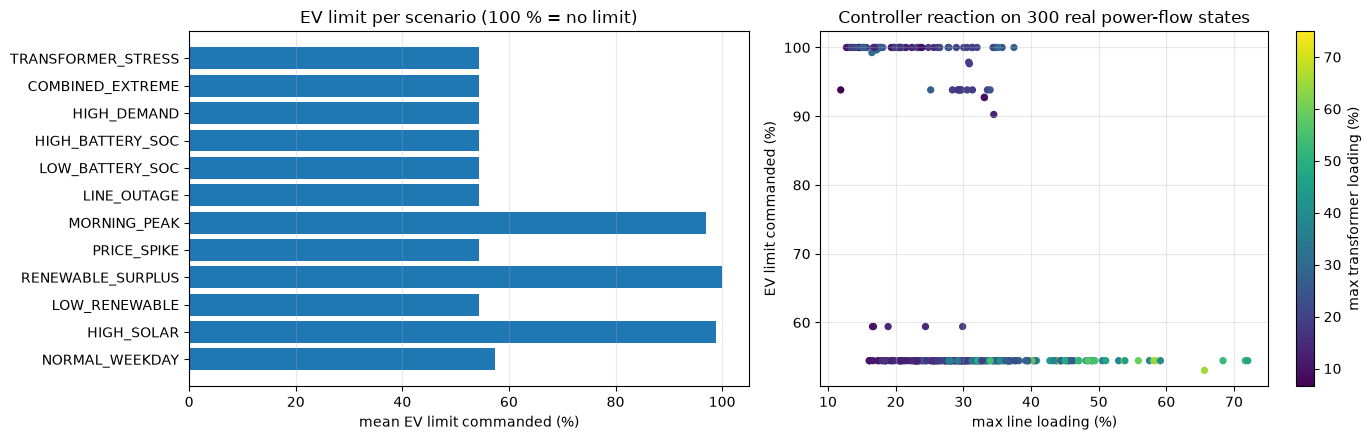

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
order = summary.sort_values("max_trafo").index
axes[0].barh(order, summary.loc[order, "mean_ev_limit"], color="tab:blue")
axes[0].set_xlabel("mean EV limit commanded (%)"); axes[0].set_xlim(0, 105)
axes[0].set_title("EV limit per scenario (100 % = no limit)"); axes[0].grid(alpha=0.3, axis="x")

sc = axes[1].scatter(replay["line"], replay["ev_limit"], c=replay["trafo"], cmap="viridis", s=18)
axes[1].set_xlabel("max line loading (%)"); axes[1].set_ylabel("EV limit commanded (%)")
axes[1].set_title("Controller reaction on 300 real power-flow states")
plt.colorbar(sc, ax=axes[1], label="max transformer loading (%)"); axes[1].grid(alpha=0.3)
fig.tight_layout(); fig.savefig("output/controller_scenario_replay.png", dpi=150); plt.show()

### What the replay shows

- **The grid itself is never stressed in these 300 states:** all of them are classified NORMAL. Voltage stays above about 0.96 pu and the highest loading is 75 % (transformer stress scenario), so the grid-protection rules (group A) never fire.
- **The controller still acts in the evening-peak scenarios, but because of price, not grid stress.** Those scenarios carry high price multipliers (1.2 to 3.0), so the price rules (group C) lower the EV limit to about 54 %, cut about 13 % of the flexible load and ask the battery to discharge. In HIGH_SOLAR and RENEWABLE_SURPLUS (low price, lots of PV) the EV limit stays at about 99-100 % and no load is cut.
- **Caution on prices:** the COMBINED_EXTREME and PRICE_SPIKE multipliers (3x) push the price above anything in the 2015-2018 training data (maximum about 113 EUR/MWh). The controller clips them at 120. Sujit's final price mapping may change these numbers.
- **Consequence for Step 7:** controller OFF vs ON cannot be shown on this library, because there is nothing for the controller to fix electrically. It has to be validated on a case that really overloads the grid, such as Sujit's 4x load stress (0.858 pu, 143 % line loading) or the heavy-EV case.

**Next:** Step 6 below, applying the commands to the network.

## Step 6 - Apply the commands to the digital twin and run the second power flow

This is the integration flow from the project plan:

`AC power flow (controller OFF)` -> `grid state` -> `fuzzy_controller` -> `apply EV limit, flexible-load cut and battery command` -> `AC power flow again (controller ON)`

**How each command is applied**

| Command | Applied to the pandapower network as |
|---|---|
| `ev_factor` | every EV bus load (`type == "EV"`, Jayanth's `ev_load_mw` per bus) is multiplied by it |
| `flex_factor` | `p_mw` and `q_mvar` of every **non-EV** load are multiplied by it |
| `battery_mw` | `p_mw` of the storage element (Sarvesh's `add_battery` / `set_battery_power`; + charge, - discharge) |

Both runs start from exactly the same base state (profile values, scenario scaling, contingencies, EV schedule), so the only difference between OFF and ON is the controller.

**Requirements:** `pandapower`, `simbench` and `numba` (the same environment as Sujit's `power_flow.ipynb`). If they are missing, the functions below are still defined and the wiring test runs, but the real power-flow cells are skipped.

In [ ]:
import json

try:
    import pandapower as pp
    import simbench as sb
    PP_OK = True
except ImportError:
    pp = sb = None
    PP_OK = False
    print("pandapower / simbench not installed here: the real power-flow cells will be skipped.")

SIMBENCH_CODE = "1-MVLV-urban-all-0-sw"
V_LOW, V_HIGH = 0.95, 1.05                      # voltage limits used by the project


DAY_START = 32928  # Start of 09.12.2016 in SimBench's 15-min profile.

def build_day_profiles(grid, start=DAY_START, n_steps=96):
    sl = slice(start, start + n_steps)

    load_rel = grid.profiles["load"].iloc[sl].copy()
    pp_rel = grid.profiles["powerplants"].iloc[sl].copy()
    re_rel = grid.profiles["renewables"].iloc[sl].copy()

    time = re_rel["time"].copy() if "time" in re_rel else None
    sgen_rel = pd.concat([
        pp_rel.drop(columns=["time"], errors="ignore"),
        re_rel.drop(columns=["time"], errors="ignore"),
    ], axis=1)

    if time is not None:
        sgen_rel["time"] = time

    return load_rel, sgen_rel

def load_digital_twin():
    grid = sb.get_simbench_net(SIMBENCH_CODE)
    load_rel, sgen_rel = build_day_profiles(grid)

    load_p = sb.get_absolute_profiles_from_relative_profiles(
        grid, element="load", multiplying_column="p_mw",
        relative_profiles=load_rel,
        profile_suffix="_pload", time_as_index=True,
    )

    load_q = sb.get_absolute_profiles_from_relative_profiles(
        grid, element="load", multiplying_column="q_mvar",
        relative_profiles=load_rel,
        profile_suffix="_qload", time_as_index=True,
    )

    renew_p = sb.get_absolute_profiles_from_relative_profiles(
        grid, element="sgen", multiplying_column="p_mw",
        relative_profiles=sgen_rel, time_as_index=True,
    )

    twin = dict(
        grid=grid, load_p=load_p, load_q=load_q, renew_p=renew_p,
        base_line_status=grid.line["in_service"].copy(),
        base_trafo_status=grid.trafo["in_service"].copy(),
    )

    with open("output/battery_config.json") as f:
        cfg = BatteryConfig(**json.load(f))

    from sarvesh_lib import add_battery

    twin["battery_cfg"] = cfg
    twin["battery_idx"] = add_battery(grid, cfg)

    return twin

In [ ]:
# ---- Applying a state and commands to the network ---------------------------------------
def apply_base_state(twin, timestamp, load_scale=1.0, renewable_scale=1.0,
                     outaged_lines=None, outaged_trafos=None):
    """Profile values + scenario scaling + contingencies. Removes EV loads. Same as run_grid() in power_flow.ipynb."""
    net = twin["grid"]
    net.load.drop(index=net.load.index[net.load["type"].eq("EV")], inplace=True)
    net.load["p_mw"] = twin["load_p"].loc[timestamp].to_numpy() * load_scale
    net.load["q_mvar"] = twin["load_q"].loc[timestamp].to_numpy() * load_scale
    net.sgen["p_mw"] = twin["renew_p"].loc[timestamp].to_numpy() * renewable_scale
    net.line["in_service"] = twin["base_line_status"].copy()
    net.trafo["in_service"] = twin["base_trafo_status"].copy()
    for idx in outaged_lines or []:
        net.line.at[idx, "in_service"] = False
    for idx in outaged_trafos or []:
        net.trafo.at[idx, "in_service"] = False


def scale_ev_loads(ev_bus_loads, factor):
    return {int(bus): float(p) * factor for bus, p in (ev_bus_loads or {}).items()}


def apply_ev_loads(net, ev_bus_loads, create_load=None):
    create_load = create_load or pp.create_load
    for bus, p_mw in ev_bus_loads.items():
        create_load(net, bus=int(bus), p_mw=float(p_mw), q_mvar=0.0, name=f"EV_Load_Bus_{bus}", type="EV")


def scale_flexible_loads(net, factor):
    """Demand response: scale every non-EV load (p and q together, so the power factor is kept)."""
    mask = ~net.load["type"].eq("EV")
    net.load.loc[mask, "p_mw"] = net.load.loc[mask, "p_mw"] * factor
    net.load.loc[mask, "q_mvar"] = net.load.loc[mask, "q_mvar"] * factor


def collect_metrics(net, converged=True):
    if not converged:
        return dict(converged=False, v_min_pu=np.nan, max_line_loading_pct=np.nan, max_trafo_loading_pct=np.nan,
                    grid_import_mw=np.nan, total_losses_mw=np.nan, voltage_violations=np.nan, overloads=np.nan,
                    violation_count=np.nan, renewable_mw=float(net.sgen["p_mw"].sum()),
                    ev_load_mw=float(net.load.loc[net.load["type"].eq("EV"), "p_mw"].sum()))
    vm = net.res_bus["vm_pu"]
    ll, tl = net.res_line["loading_percent"], net.res_trafo["loading_percent"]
    v_bad = int(((vm < V_LOW) | (vm > V_HIGH)).sum())
    over = int((ll > 100).sum() + (tl > 100).sum())
    return dict(
        converged=True,
        v_min_pu=float(np.nanmin(vm)),
        max_line_loading_pct=float(np.nanmax(ll)),
        max_trafo_loading_pct=float(np.nanmax(tl)),
        grid_import_mw=float(net.res_ext_grid["p_mw"].sum()),
        total_losses_mw=float(net.res_line["pl_mw"].sum() + net.res_trafo["pl_mw"].sum()),
        voltage_violations=v_bad, overloads=over, violation_count=v_bad + over,
        renewable_mw=float(net.sgen["p_mw"].sum()),
        ev_load_mw=float(net.load.loc[net.load["type"].eq("EV"), "p_mw"].sum()),
    )


def solve(net):
    """AC power flow (Newton-Raphson, as in Sujit's solve_grid) returning the metrics dict."""
    try:
        pp.runpp(net, algorithm="nr", init="auto")
    except pp.LoadflowNotConverged:
        return collect_metrics(net, converged=False)
    return collect_metrics(net, converged=True)

In [ ]:
# ---- OFF -> controller -> ON ---------------------------------------------------------------
def before_after(twin, timestamp, ev_bus_loads=None, pso_battery_mw=0.0, price_eur_mwh=60.0,
                 battery_energy_mwh=None, load_scale=1.0, renewable_scale=1.0,stability_risk=0.0,
                 outaged_lines=None, outaged_trafos=None, solver=None, create_load=None,
                 enable=("ev", "flex", "battery")):
    """Run the same state twice: controller OFF (plan only) and controller ON (fuzzy commands applied)."""
    solver = solver or solve
    net, cfg, sidx = twin["grid"], twin["battery_cfg"], twin["battery_idx"]
    if battery_energy_mwh is None:
        battery_energy_mwh = cfg.e_init
    soc_pct = battery_energy_mwh / cfg.e_cap_mwh * 100.0
    state_kwargs = dict(load_scale=load_scale, renewable_scale=renewable_scale,
                        outaged_lines=outaged_lines, outaged_trafos=outaged_trafos)

    # Pass 1 - controller OFF: EV schedule as planned, battery follows the PSO plan
    apply_base_state(twin, timestamp, **state_kwargs)
    apply_ev_loads(net, scale_ev_loads(ev_bus_loads, 1.0), create_load)
    set_battery_power(net, sidx, pso_battery_mw)
    off = solver(net)

    # Controller: sees the state produced by pass 1
    grid_state = build_grid_state(
        off,
        price_eur_mwh=price_eur_mwh,
        battery_soc_pct=soc_pct,
        stability_risk=stability_risk,
    )          # renewable_mw and ev_load_mw come from `off`
    commands = fuzzy_controller(grid_state, pso_battery_mw=pso_battery_mw,
                                battery_cfg=cfg, battery_energy_mwh=battery_energy_mwh)

    # Pass 2 - controller ON: identical base state, then the commands
    apply_base_state(twin, timestamp, **state_kwargs)
    ev_f = commands["ev_factor"] if "ev" in enable else 1.0              # `enable` lets Step 7 test one command at a time
    flex_f = commands["flex_factor"] if "flex" in enable else 1.0
    batt_mw = commands["battery_mw"] if "battery" in enable else pso_battery_mw
    apply_ev_loads(net, scale_ev_loads(ev_bus_loads, ev_f), create_load)
    scale_flexible_loads(net, flex_f)
    set_battery_power(net, sidx, batt_mw)
    on = solver(net)

    return dict(timestamp=timestamp, off=off, on=on, commands=commands, grid_state=grid_state)


LOWER_IS_BETTER = {"max_line_loading_pct": True, "max_trafo_loading_pct": True, "total_losses_mw": True,
                   "grid_import_mw": True, "violation_count": True, "v_min_pu": False}

def compare(result):
    rows = []
    for name, lower_better in LOWER_IS_BETTER.items():
        a, b = result["off"][name], result["on"][name]
        if np.isnan(a) and np.isnan(b):
            verdict = "n/a"
        elif np.isnan(a):
            verdict = "restored"                         # OFF run failed to converge, ON run did
        elif np.isnan(b):
            verdict = "no"
        else:
            better = (b < a) if lower_better else (b > a)
            verdict = "yes" if better else ("equal" if np.isclose(a, b) else "no")
        rows.append(dict(metric=name, controller_OFF=a, controller_ON=b, change=b - a, improved=verdict))
    return pd.DataFrame(rows).set_index("metric")

### Test 1 - wiring test (runs without pandapower)

This checks that every command really reaches the network tables: EV loads, non-EV loads and the battery. It uses a small fake network and a **toy solver** whose numbers are meaningless (more load simply means lower voltage and higher loading). Only the wiring is tested here, not the physics.

In [ ]:
from types import SimpleNamespace

def make_fake_twin():
    ts = ["T0"]
    net = SimpleNamespace(
        load=pd.DataFrame({"bus": [1, 2, 3], "p_mw": [1.0, 2.0, 3.0], "q_mvar": [0.3, 0.6, 0.9], "type": [None, None, None]}),
        sgen=pd.DataFrame({"p_mw": [0.5]}),
        line=pd.DataFrame({"in_service": [True, True]}),
        trafo=pd.DataFrame({"in_service": [True]}),
        storage=pd.DataFrame({"p_mw": [0.0]}),
    )
    return dict(grid=net,
                load_p=pd.DataFrame([[1.0, 2.0, 3.0]], index=ts), load_q=pd.DataFrame([[0.3, 0.6, 0.9]], index=ts),
                renew_p=pd.DataFrame([[0.5]], index=ts),
                base_line_status=net.line["in_service"].copy(), base_trafo_status=net.trafo["in_service"].copy(),
                battery_cfg=BatteryConfig(), battery_idx=0)

def fake_create_load(net, bus, p_mw, q_mvar, name, type):
    net.load.loc[len(net.load) + 100] = dict(bus=bus, p_mw=p_mw, q_mvar=q_mvar, type=type)

def fake_set_battery_power(net, sidx, p_mw):          # same effect as sarvesh_lib.set_battery_power
    net.storage.at[sidx, "p_mw"] = float(p_mw)

def toy_solver(net):                                    # NOT physics: only monotone in load
    total = net.load["p_mw"].sum() + net.storage["p_mw"].sum() - net.sgen["p_mw"].sum()
    net.res_bus = pd.DataFrame({"vm_pu": [1.0, 1.05 - 0.02 * total]})
    net.res_line = pd.DataFrame({"loading_percent": [10 * total], "pl_mw": [0.01 * total]})
    net.res_trafo = pd.DataFrame({"loading_percent": [8 * total], "pl_mw": [0.005 * total]})
    net.res_ext_grid = pd.DataFrame({"p_mw": [total]})
    return collect_metrics(net, True)

# Wiring uses the real functions; only the pandapower-specific calls are replaced
_real_set_battery = set_battery_power
set_battery_power = fake_set_battery_power

twin = make_fake_twin()
ev = {10: 1.0, 11: 1.0}                                 # 2 MW of EV charging on two buses
res = before_after(twin, "T0", ev_bus_loads=ev, pso_battery_mw=0.0, price_eur_mwh=95.0,
                   load_scale=4.0, renewable_scale=0.2, solver=toy_solver, create_load=fake_create_load)
cmd = res["commands"]
net = twin["grid"]
print({k: (round(v, 3) if isinstance(v, float) else v) for k, v in cmd.items()})

# EV: total EV load of the ON run equals planned load x ev_factor
assert abs(res["on"]["ev_load_mw"] - 2.0 * cmd["ev_factor"]) < 1e-9
assert abs(res["off"]["ev_load_mw"] - 2.0) < 1e-9
# Non-EV load: equals scaled base load x flex_factor (OFF run had factor 1)
base_load = 6.0 * 4.0
non_ev = net.load.loc[~net.load["type"].eq("EV"), "p_mw"].sum()
assert abs(non_ev - base_load * cmd["flex_factor"]) < 1e-9
# Battery: storage set-point equals the controller's final command
assert abs(net.storage.at[0, "p_mw"] - cmd["battery_mw"]) < 1e-9
# Same base state in both runs: renewable generation identical
assert res["off"]["renewable_mw"] == res["on"]["renewable_mw"]
# The toy network gets lighter, so no metric may get worse in the comparison table
table = compare(res)
print(table.round(3).to_string())
assert not (table["improved"] == "no").any()          # nothing got worse on the toy network
assert table.loc["v_min_pu", "improved"] == "yes"
set_battery_power = _real_set_battery                    # restore Sarvesh's function
print("Wiring test passed: EV limit, flexible-load cut and battery command all reach the network.")

### Test 2 - real power flow (run this on your machine, needs pandapower + simbench)

One smoke test on Sujit's known stress case: **4x load, 20 % renewable, 09.12.2016 18:15**, with Jayanth's GA EV schedule at the same time of day, the PSO battery set-point and Sujit's price forecast for that step. It confirms that the whole chain runs and the controller changes the network. It is not yet the final validation (that is Step 7).

In [ ]:
if not PP_OK:
    print("Skipped: pandapower / simbench not available in this environment.")
else:
    twin = load_digital_twin()
    net = twin["grid"]

    TS = "09.12.2016 18:15"                      # peak timestamp used in power_flow.ipynb
    STEP = 73                                    # 18:15 = step 73 of the 96-step day

    ev_df = pd.read_csv("data/ev_optimized_profiles.csv")
    ev_step_ts = sorted(ev_df["timestamp"].unique())[STEP]
    ev_bus_loads = ev_df[ev_df["timestamp"] == ev_step_ts].set_index("bus")["ev_load_mw"].to_dict()
    assert set(ev_bus_loads) <= set(net.bus.index), "EV buses must exist in the SimBench network"

    pso_mw = pd.read_csv("output/battery_schedule_pso_96.csv")["battery_power_mw"].iloc[STEP]
    price = pd.read_csv("output/price_forecast_day.csv")["price_forecast"].iloc[STEP]

    result = before_after(twin, TS, ev_bus_loads=ev_bus_loads, pso_battery_mw=float(pso_mw),
                          price_eur_mwh=float(price), load_scale=4.0, renewable_scale=0.2)
    print("Controller input :", {k: round(v, 3) for k, v in result["grid_state"].items()} if result["grid_state"] else "invalid -> fallback")
    print("Commands         :", {k: (round(v, 3) if isinstance(v, float) else v) for k, v in result["commands"].items()})
    print(compare(result).round(3).to_string())

### Design notes (for the viva)

- **Same base state twice:** `apply_base_state` rebuilds loads, generation and contingencies from the profiles before each run, so OFF vs ON differ only by the controller.
- **Flexible load = every non-EV load**, scaled in P and Q together. The cut is `FLEX_SHARE x reduction %` (30 % x up to 30 % = at most 9 % of non-EV demand).
- **Battery** uses Sarvesh's storage element, and `battery_dispatch` already clipped the command to SOC and power limits.
- **If the first power flow fails**, the controller gets no valid state and returns the safe fallback command, so the second run still happens.

**Next:** Step 7 below, the OFF vs ON validation.

## Step 7 - Controller OFF vs ON validation

The same stressed scenario is solved twice (Step 6): without the controller and with the controller's commands applied. The comparison covers the six metrics required by the project plan: **minimum voltage, maximum line loading, transformer loading, losses, grid import and violation count.**

**Scenarios** (all at 09.12.2016 18:15, the evening peak used in `power_flow.ipynb`; EV schedule = Jayanth's `GA_OPT_MEDIUM` at the same time of day, battery = PSO set-point, price = Sujit's forecast for that step):

| Scenario | Load | Renewable | EV load | Contingency | Purpose |
|---|---|---|---|---|---|
| `NORMAL_CONTROL` | x1.0 | x1.0 | x1 | none | the controller must not harm a healthy grid |
| `EV_HEAVY_2X` | x1.0 | x1.0 | x2 | none | EV-driven stress (the hosting-capacity study shows line overloads at about 20 % penetration) |
| `EV_HEAVY_3X` | x1.0 | x1.0 | x3 | none | stronger EV stress |
| `DEMAND_STRESS_4X` | x4.0 | x0.2 | x1 | none | Sujit's stress case |
| `COMBINED_EXTREME` | x2.5 | x0.1 | x2 | line 10229 out | Sarvesh's extreme multipliers with a line outage |

Besides the scenario table, there is a **load sweep** (OFF vs ON as demand grows) and an **ablation** (EV limit only, flexible load only, battery only, all three) to show which command does the work.

In [ ]:
VALIDATION_TS = "09.12.2016 18:15"
VALIDATION_STEP = 73                                  # 18:15 = step 73 of the 96-step day

SCENARIOS = [
    dict(name="NORMAL_CONTROL",   load_scale=1.0, renewable_scale=1.0, ev_scale=1.0),
    dict(name="EV_HEAVY_2X",      load_scale=1.0, renewable_scale=1.0, ev_scale=2.0),
    dict(name="EV_HEAVY_3X",      load_scale=1.0, renewable_scale=1.0, ev_scale=3.0),
    dict(name="DEMAND_STRESS_4X", load_scale=4.0, renewable_scale=0.2, ev_scale=1.0),
    dict(name="COMBINED_EXTREME", load_scale=2.5, renewable_scale=0.1, ev_scale=2.0, outaged_lines=[10229]),
]
METRICS = list(LOWER_IS_BETTER)                       # the six required metrics


def run_scenario(twin, sc, ev_base, pso_mw, price, timestamp=VALIDATION_TS, enable=("ev", "flex", "battery"),
                 solver=None, create_load=None):
    ev = {b: p * sc.get("ev_scale", 1.0) for b, p in ev_base.items()}
    return before_after(twin, timestamp, ev_bus_loads=ev, pso_battery_mw=pso_mw, price_eur_mwh=price,
                        load_scale=sc["load_scale"], renewable_scale=sc["renewable_scale"],
                        outaged_lines=sc.get("outaged_lines"), enable=enable,
                        solver=solver, create_load=create_load)


def run_validation(twin, scenarios, ev_base, pso_mw, price, **kw):
    long_rows, cmd_rows = [], []
    for sc in scenarios:
        res = run_scenario(twin, sc, ev_base, pso_mw, price, **kw)
        for metric, r in compare(res).iterrows():
            long_rows.append(dict(scenario=sc["name"], metric=metric, controller_OFF=r["controller_OFF"],
                                  controller_ON=r["controller_ON"], change=r["change"], improved=r["improved"]))
        c = res["commands"]
        cmd_rows.append(dict(scenario=sc["name"], grid_state=c["grid_state"], ev_limit_pct=c["ev_limit_pct"],
                             battery_mw=c["battery_mw"], flex_reduction_pct=c["flex_reduction_pct"],
                             fallback=c["fallback"], converged_OFF=res["off"]["converged"],
                             converged_ON=res["on"]["converged"],action=c["action"],))
    return pd.DataFrame(long_rows), pd.DataFrame(cmd_rows)


def run_sweep(twin, load_scales, ev_base, pso_mw, price, renewable_scale=0.2, **kw):
    rows = []
    for ls in load_scales:
        res = run_scenario(twin, dict(name=f"x{ls}", load_scale=ls, renewable_scale=renewable_scale),
                           ev_base, pso_mw, price, **kw)
        rows.append(dict(load_scale=ls, v_min_OFF=res["off"]["v_min_pu"], v_min_ON=res["on"]["v_min_pu"],
                         line_OFF=res["off"]["max_line_loading_pct"], line_ON=res["on"]["max_line_loading_pct"],
                         trafo_OFF=res["off"]["max_trafo_loading_pct"], trafo_ON=res["on"]["max_trafo_loading_pct"],
                         ev_limit_pct=res["commands"]["ev_limit_pct"], grid_state=res["commands"]["grid_state"]))
    return pd.DataFrame(rows)


ABLATION_VARIANTS = {"controller OFF": None, "EV limit only": ("ev",), "flexible load only": ("flex",),
                     "battery only": ("battery",), "all three": ("ev", "flex", "battery")}

def run_ablation(twin, sc, ev_base, pso_mw, price, **kw):
    rows = []
    for label, enable in ABLATION_VARIANTS.items():
        res = run_scenario(twin, sc, ev_base, pso_mw, price, enable=enable or (), **kw)
        m = res["off"] if enable is None else res["on"]
        rows.append(dict(variant=label, **{k: m[k] for k in METRICS}))
    return pd.DataFrame(rows).set_index("variant")


def summarize(long_df):
    lines = []
    for metric in METRICS:
        sub = long_df[long_df["metric"] == metric]
        lines.append(f"{metric:22s} improved in {int((sub['improved'] == 'yes').sum())}/{len(sub)} scenarios, "
                     f"worse in {int((sub['improved'] == 'no').sum())}")
    return "\n".join(lines)

In [ ]:
def plot_validation(long_df, path):
    titles = {"v_min_pu": "Minimum voltage (pu)", "max_line_loading_pct": "Max line loading (%)",
              "max_trafo_loading_pct": "Max transformer loading (%)", "total_losses_mw": "Losses (MW)",
              "grid_import_mw": "Grid import (MW)", "violation_count": "Violations (count)"}
    fig, axes = plt.subplots(2, 3, figsize=(16, 8))
    for ax, metric in zip(axes.ravel(), METRICS):
        sub = long_df[long_df["metric"] == metric].set_index("scenario")
        x = np.arange(len(sub)); w = 0.38
        ax.bar(x - w / 2, sub["controller_OFF"], w, label="controller OFF", color="tab:red")
        ax.bar(x + w / 2, sub["controller_ON"], w, label="controller ON", color="tab:green")
        if metric == "v_min_pu":
            ax.axhline(V_LOW, color="k", linestyle=":", label="0.95 pu limit")
        if "loading" in metric:
            ax.axhline(100, color="k", linestyle=":", label="100 % limit")
        ax.set_xticks(x); ax.set_xticklabels(sub.index, rotation=30, ha="right", fontsize=8)
        ax.set_title(titles[metric]); ax.grid(alpha=0.3, axis="y")
    axes[0, 0].legend(fontsize=8)
    fig.suptitle("Fuzzy controller: OFF vs ON", fontsize=14)
    fig.tight_layout(); fig.savefig(path, dpi=150); plt.show()


def plot_sweep(sweep_df, path):
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
    for ax, (off, on, label, limit) in zip(axes, [("v_min_OFF", "v_min_ON", "Minimum voltage (pu)", V_LOW),
                                                  ("line_OFF", "line_ON", "Max line loading (%)", 100),
                                                  ("trafo_OFF", "trafo_ON", "Max transformer loading (%)", 100)]):
        ax.plot(sweep_df["load_scale"], sweep_df[off], "o-", color="tab:red", label="controller OFF")
        ax.plot(sweep_df["load_scale"], sweep_df[on], "o-", color="tab:green", label="controller ON")
        ax.axhline(limit, color="k", linestyle=":")
        ax.set_xlabel("load multiplier"); ax.set_title(label); ax.grid(alpha=0.3)
    axes[0].legend()
    fig.suptitle("Demand sweep: OFF vs ON", fontsize=14)
    fig.tight_layout(); fig.savefig(path, dpi=150); plt.show()

### Test 1 - wiring test of the validation code (runs without pandapower)

Runs the full validation, sweep, ablation and plotting code on the toy network of Step 6 and checks the shapes and that the plots are written. **The numbers are meaningless** (toy solver), so these plots are written to a temporary folder, not to `output/`.

In [ ]:
import tempfile

_real_set_battery = set_battery_power
set_battery_power = fake_set_battery_power

toy_scenarios = [sc for sc in SCENARIOS if not sc.get("outaged_lines")]       # the toy net has no line 10229
twin = make_fake_twin()
ev_toy = {10: 1.0, 11: 1.0}
kw = dict(timestamp="T0", solver=toy_solver, create_load=fake_create_load)

long_df, cmd_df = run_validation(twin, toy_scenarios, ev_toy, 0.0, 65.0, **kw)
assert len(long_df) == len(toy_scenarios) * len(METRICS) and len(cmd_df) == len(toy_scenarios)
assert set(long_df["metric"]) == set(METRICS)
assert not long_df["improved"].eq("no").any()

sweep_df = run_sweep(twin, [1.0, 2.0, 3.0], ev_toy, 0.0, 65.0, **kw)
assert len(sweep_df) == 3

abl = run_ablation(twin, toy_scenarios[-1], ev_toy, 0.0, 65.0, **kw)
assert list(abl.index) == list(ABLATION_VARIANTS) and list(abl.columns) == METRICS

tmp = tempfile.gettempdir()
plot_validation(long_df, f"{tmp}/toy_validation.png")
plot_sweep(sweep_df, f"{tmp}/toy_sweep.png")
print(summarize(long_df))

set_battery_power = _real_set_battery
print("Validation wiring test passed (toy numbers, not results).")

### Test 2 - real validation (run this on your machine, needs pandapower + simbench)

Writes four files to `output/`: `controller_validation.csv`, `controller_commands.csv`, `controller_validation.png`, `controller_sweep.png` and `controller_ablation.csv`.

In [ ]:
if not PP_OK:
    print("Skipped: pandapower / simbench not available in this environment.")
else:
    twin = load_digital_twin()
    net = twin["grid"]

    ev_df = pd.read_csv("data/ev_optimized_profiles.csv")
    ev_ts = sorted(ev_df["timestamp"].unique())[VALIDATION_STEP]
    ev_base = ev_df[ev_df["timestamp"] == ev_ts].set_index("bus")["ev_load_mw"].to_dict()
    assert set(ev_base) <= set(net.bus.index), "EV buses must exist in the SimBench network"

    pso_mw = float(pd.read_csv("output/battery_schedule_pso_96.csv")["battery_power_mw"].iloc[VALIDATION_STEP])
    price = float(pd.read_csv("output/price_forecast_day.csv")["price_forecast"].iloc[VALIDATION_STEP])
    print(f"EV load at 18:15: {sum(ev_base.values()):.2f} MW | PSO battery: {pso_mw:.2f} MW | price: {price:.1f} EUR/MWh")

    long_df, cmd_df = run_validation(twin, SCENARIOS, ev_base, pso_mw, price)
    long_df.to_csv("output/controller_validation.csv", index=False)
    cmd_df.to_csv("output/controller_commands.csv", index=False)

    print("\nCommands issued:")
    print(cmd_df.round(2).to_string(index=False))
    print("\nOFF vs ON:")
    print(long_df.pivot(index="scenario", columns="metric", values="controller_OFF").round(2)[METRICS].to_string())
    print()
    print(long_df.pivot(index="scenario", columns="metric", values="controller_ON").round(2)[METRICS].to_string())
    print("\n" + summarize(long_df))
    plot_validation(long_df, "output/controller_validation.png")

In [ ]:
if PP_OK:
    sweep_df = run_sweep(twin, [1.0, 1.5, 2.0, 2.5, 3.0, 3.5, 4.0], ev_base, pso_mw, price)
    sweep_df.to_csv("output/controller_sweep.csv", index=False)
    print(sweep_df.round(2).to_string(index=False))
    plot_sweep(sweep_df, "output/controller_sweep.png")

    ablation = run_ablation(twin, SCENARIOS[3], ev_base, pso_mw, price)       # DEMAND_STRESS_4X
    ablation.to_csv("output/controller_ablation.csv")
    print("\nAblation on DEMAND_STRESS_4X:")
    print(ablation.round(2).to_string())

### How to read the results (for the viva)

- **NORMAL_CONTROL:** nothing should get worse. If the controller still changes the EV limit there, the cause is the price rules (forecast at 18:15 sits in the HIGH price range), not grid stress.
- **Stressed scenarios:** look for higher minimum voltage, lower line and transformer loading, fewer violations. The cut in EV charging and flexible load is what relieves the grid; the battery helps by discharging.
- **Ablation:** shows which of the three commands matters most. Expect the EV limit to do most of the work in the EV scenarios and the flexible-load cut in the demand-stress case.
- **Limits of the method:** the controller is rule-based. It reduces stress but does not guarantee zero violations, and if the grid is infeasible even at the 10 % EV floor and 30 % flexible cut, violations remain.
- **Honest reporting:** report the numbers exactly as the run produces them, including scenarios where the improvement is small.

**Next (Step 8):** final documentation: membership-function and rule-base tables, plots, and the viva answers.